# Ertangi guruch sarfi va tushum bashorati

**Ma'lumot:** `data/sales.csv`. Oshxonaning 900 kunlik savdosi (2023-01-01 → 2025-06-18).

**Bashorat qilinadi (ertangi kun uchun):**
1. `rice_kg`: ishlatiladigan guruch, kg
2. `revenue_uzs`: tushum, so'm

**Savollar:** nima ta'sir qiladi, qaysi model eng yaxshi (sklearn va Keras/TensorFlow), 95% aniqlikka chiqa olamizmi?

Tayyor model va uni ishlatish skripti [`../model/`](../model/README.md) papkasida.

In [1]:
import os, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # TensorFlow'ning texnik loglarini o'chirish

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

import tensorflow as tf
import keras
tf.get_logger().setLevel("ERROR")

sys.path.append("../model")
from train import build_model, TARGETS            # yakuniy model bilan aynan bir xil pipeline
from predict import prepare_features, predict

df = pd.read_csv("../data/sales.csv", parse_dates=["date"])
bool_cols = df.select_dtypes("bool").columns
df[bool_cols] = df[bool_cols].astype(int)

print(df.shape, "| bo'sh qiymatlar:", df.isna().sum().sum(), "| TensorFlow", tf.__version__, "| Keras", keras.__version__)
df[["date", "customers", "rice_kg", "revenue_uzs", "temp_c", "promotion", "salary_week"]].head(3)

(900, 21) | bo'sh qiymatlar: 0 | TensorFlow 2.21.0 | Keras 3.15.1


,date,customers,rice_kg,revenue_uzs,temp_c,promotion,salary_week
0,2023-01-01,194,44.6,10698182,0.4,0,0
1,2023-01-02,116,27.1,6270691,2.8,0,0
2,2023-01-03,173,40.2,9654998,-1.7,0,1


## 1. Guruch va tushum: asosiy manzara

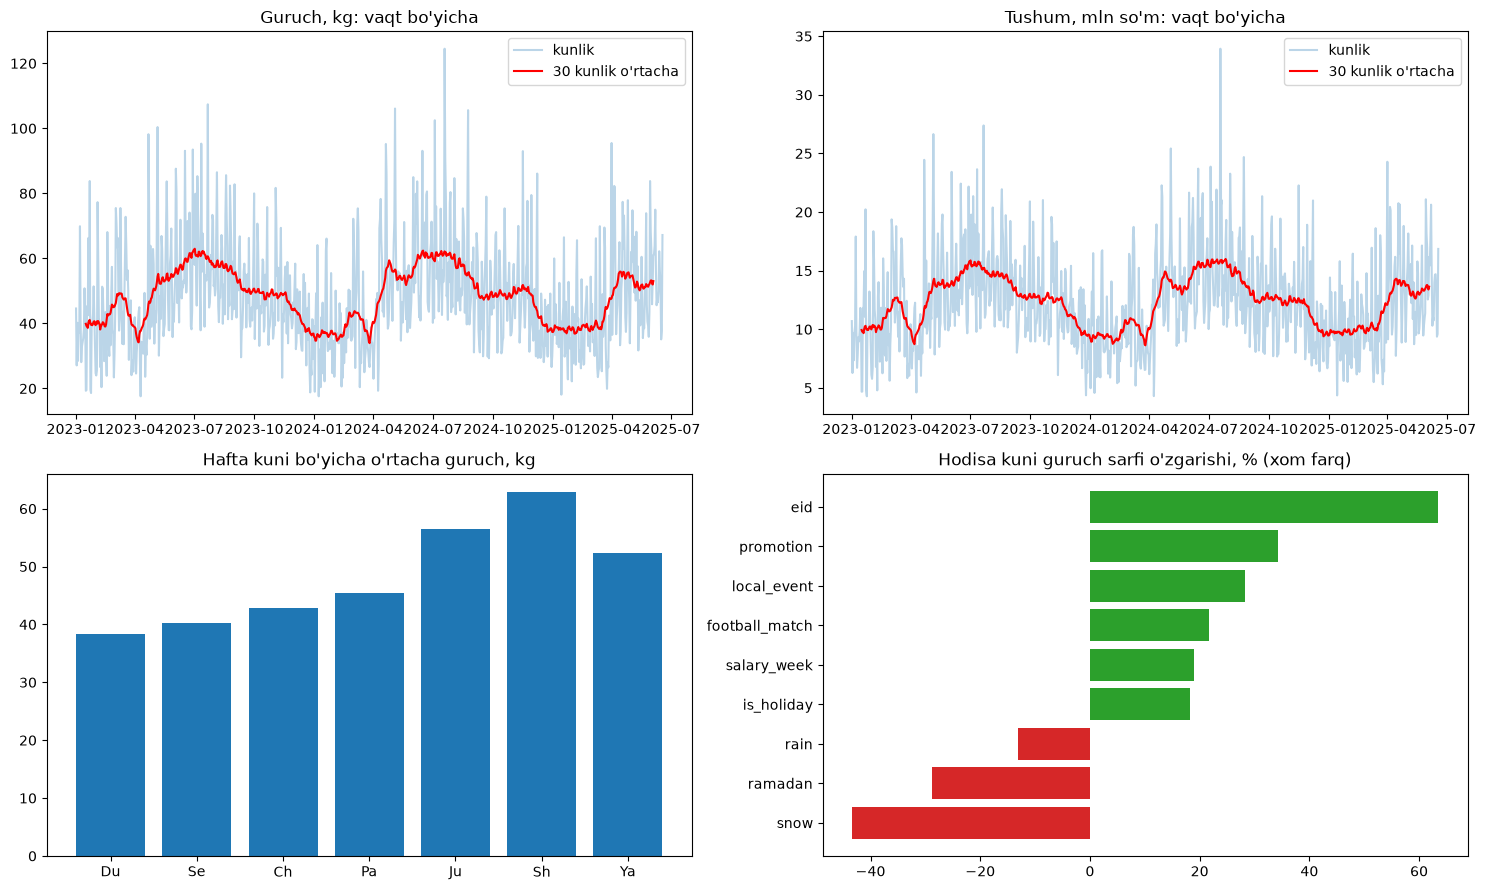

In [2]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

for a, t, title in [(ax[0, 0], "rice_kg", "Guruch, kg"), (ax[0, 1], "revenue_uzs", "Tushum, mln so'm")]:
    s = df.set_index("date")[t] / (1e6 if t == "revenue_uzs" else 1)
    a.plot(s, alpha=0.3, label="kunlik")
    a.plot(s.rolling(30, center=True).mean(), color="red", label="30 kunlik o'rtacha")
    a.set_title(f"{title}: vaqt bo'yicha"); a.legend()

days = ["Du", "Se", "Ch", "Pa", "Ju", "Sh", "Ya"]
ax[1, 0].bar(days, df.groupby("weekday").rice_kg.mean())
ax[1, 0].set_title("Hafta kuni bo'yicha o'rtacha guruch, kg")

events = ["eid", "promotion", "local_event", "football_match", "salary_week", "is_holiday", "rain", "ramadan", "snow"]
lift = pd.Series({e: (df[df[e] == 1].rice_kg.mean() / df[df[e] == 0].rice_kg.mean() - 1) * 100 for e in events}).sort_values()
ax[1, 1].barh(lift.index, lift, color=np.where(lift > 0, "tab:green", "tab:red"))
ax[1, 1].set_title("Hodisa kuni guruch sarfi o'zgarishi, % (xom farq)")

plt.tight_layout(); plt.show()

In [3]:
# Bitta mijozga: guruch deyarli o'zgarmas, tushum esa oylik haftasida oshadi
d = df.assign(rice_per_customer=df.rice_kg / df.customers, revenue_per_customer=df.revenue_uzs / df.customers)
pd.DataFrame({
    "o'rtacha":           d[["rice_per_customer", "revenue_per_customer"]].mean(),
    "oylik haftasi":      d[d.salary_week == 1][["rice_per_customer", "revenue_per_customer"]].mean(),
    "oddiy hafta":        d[d.salary_week == 0][["rice_per_customer", "revenue_per_customer"]].mean(),
}).round(3)

,o'rtacha,oylik haftasi,oddiy hafta
rice_per_customer,0.220,0.220,0.220
revenue_per_customer,55906.737,57463.855,55143.646


**Xulosalar:**
- Guruch va tushum **bir xil ritmda** harakatlanadi: ikkalasi ham mijozlar soniga bog'liq. Bitta mijozga ~0.22 kg guruch va ~56 ming so'm to'g'ri keladi.
- Haftaning eng ko'p sarfli kunlari **juma va shanba**. Hayit, aksiya, tadbir va oylik haftasi sarfni oshiradi, **Ramazon va qor** esa eng kuchli pasaytiradi.
- **Oylik haftasida** odamlar nafaqat ko'proq keladi, balki har biri ~4% ko'proq pul sarflaydi. Shuning uchun tushumni alohida model bilan bashorat qilamiz.

## 2. ⚠️ Data leakage: qaysi ustunlarni ishlata olmaymiz

`customers`, `salad_count` (va guruch uchun `revenue_uzs`, tushum uchun `rice_kg`) kun **tugagandan keyin** ma'lum bo'ladi. Ertangi kunni bashorat qilayotganda ular yo'q. Agar ularni modelga qo'shsak:

In [4]:
split = len(df) - 180                     # vaqt bo'yicha: oxirgi 180 kun test
train, test = df.iloc[:split], df.iloc[split:]

leak = ["customers", "salad_count"]
p = LinearRegression().fit(train[leak], train.rice_kg).predict(test[leak])
print(f"Leakage bilan guruch 'aniqligi': {100 - mean_absolute_percentage_error(test.rice_kg, p) * 100:.1f}%  ← soxta!")

Leakage bilan guruch 'aniqligi': 95.6%  ← soxta!


Bu natija soxta: real hayotda ertangi mijozlar sonini oldindan bilmaymiz. Modelga faqat **kun boshida ma'lum** bo'lgan ma'lumotni beramiz: sana, ob-havo prognozi, bayram, Ramazon, oylik haftasi, aksiya rejasi, tadbirlar.

## 3. Modellar bellashuvi: sklearn va Keras/TensorFlow

- **Test:** oxirgi 180 kun (2024-12-21 → 2025-06-18). Model bu kunlarni o'qitishda ko'rmaydi.
- **Log target:** ta'sirlar foizda ishlaydi (aksiya ≈ +30%), shuning uchun `log(target)` bashorat qilinadi.
- **Aniqlik** = 100% − MAPE (o'rtacha foizdagi xato).

In [5]:
X_train, X_test = prepare_features(train), prepare_features(test)

def score(y_true, pred):
    ape = np.abs(pred - y_true) / y_true
    return {"Aniqlik %": round(100 - ape.mean() * 100, 1), "R²": round(r2_score(y_true, pred), 3),
            "MAE": round(mean_absolute_error(y_true, pred), 1), "±10% ichida, kunlar %": round((ape <= 0.10).mean() * 100)}

def keras_model(hidden, n_inputs):
    layers = [keras.Input(shape=(n_inputs,))]
    for units in hidden:
        layers += [keras.layers.Dense(units, activation="relu"), keras.layers.Dropout(0.1)]
    model = keras.Sequential(layers + [keras.layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model

rows, histories, ridge_models = {}, {}, {}
for t in TARGETS:
    y_tr, y_te = train[t], test[t]
    rows[(t, "Baseline: 7 kun oldingi qiymat")] = score(y_te, df[t].shift(7).iloc[split:].values)

    ridge = build_model().fit(X_train, np.log(y_tr))
    ridge_models[t] = ridge
    rows[(t, "Ridge (log)")] = score(y_te, np.exp(ridge.predict(X_test)))

    gb = GradientBoostingRegressor(n_estimators=600, learning_rate=0.02, max_depth=2, random_state=42)
    gb.fit(X_train, np.log(y_tr))
    rows[(t, "Gradient Boosting (log)")] = score(y_te, np.exp(gb.predict(X_test)))

    # Keras: Ridge bilan bir xil preprocessing (one-hot + scaling), target log + standartlashtirilgan
    prep = build_model()[0].fit(X_train)
    dense = lambda a: (a.toarray() if hasattr(a, "toarray") else a).astype("float32")
    Xtr, Xte = dense(prep.transform(X_train)), dense(prep.transform(X_test))
    mu, sd = np.log(y_tr).mean(), np.log(y_tr).std()
    for name, hidden in [("Keras linear", []), ("Keras MLP (32)", [32])]:
        keras.utils.set_random_seed(42)
        m = keras_model(hidden, Xtr.shape[1])
        h = m.fit(Xtr, ((np.log(y_tr) - mu) / sd).values.astype("float32"), validation_split=0.2,
                  epochs=500, batch_size=32, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)])
        histories[(t, name)] = h.history
        rows[(t, name)] = score(y_te, np.exp(m.predict(Xte, verbose=0).ravel() * sd + mu))

results = pd.DataFrame(rows).T
results.index.names = ["target", "model"]
results.sort_values(["target", "Aniqlik %"], ascending=[True, False])

Aniqlik %     R²        MAE  \
target      model                                                         
revenue_uzs Ridge (log)                          92.5  0.908   868551.5   
            Keras linear                         92.3  0.902   886987.6   
            Keras MLP (32)                       91.7  0.847   998918.7   
            Gradient Boosting (log)              91.6  0.866   960655.5   
            Baseline: 7 kun oldingi qiymat       71.7 -0.270  3149394.7   
rice_kg     Ridge (log)                          91.5  0.887        3.8   
            Keras linear                         91.4  0.884        3.8   
            Keras MLP (32)                       90.9  0.834        4.2   
            Gradient Boosting (log)              90.3  0.857        4.3   
            Baseline: 7 kun oldingi qiymat       72.5 -0.228       12.2   

                                            ±10% ichida, kunlar %  
target      model                                                  
revenue_uzs Ridge (log)                                      72.0  
            Keras linear                                     71.0  
            Keras MLP (32)                                   66.0  
            Gradient Boosting (log)                          66.0  
            Baseline: 7 kun oldingi qiymat                   25.0  
rice_kg     Ridge (log)                                      69.0  
            Keras linear                                     65.0  
            Keras MLP (32)                                   66.0  
            Gradient Boosting (log)                          57.0  
            Baseline: 7 kun oldingi qiymat                   23.0

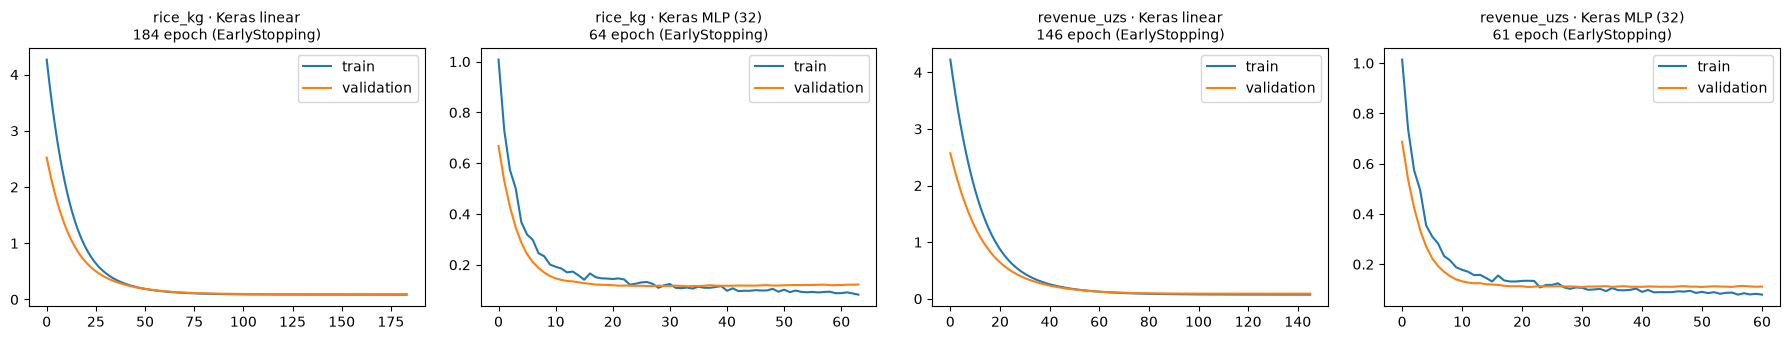

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for a, ((t, name), hist) in zip(ax, histories.items()):
    a.plot(hist["loss"], label="train"); a.plot(hist["val_loss"], label="validation")
    a.set_title(f"{t} · {name}\n{len(hist['loss'])} epoch (EarlyStopping)", fontsize=10); a.legend()
plt.tight_layout(); plt.show()

**Natija:**
- Ikkala target uchun ham g'olib **Ridge (log)** bo'ldi. **Keras linear** deyarli bir xil natija beradi. Bu ajablanarli emas: matematik jihatdan bu bitta model, faqat Ridge formula bilan, Keras esa gradient descent bilan yechiladi.
- **Keras MLP** va **Gradient Boosting** yomonroq chiqdi. Train'da atigi ~720 kun bor, bog'liqlik esa log'dan keyin deyarli chiziqli. Murakkab model yangi naqsh topmaydi, faqat shovqinni yodlab oladi. Neyron tarmoqlar o'n minglab qatorli ma'lumotda ustun chiqadi.
- **EarlyStopping** grafiklari: validation loss tushishdan to'xtagan joyda o'qitish to'xtaydi va overfitting'ning oldi olinadi.

## 4. 95% aniqlikka chiqa olamizmi?

rice_kg      train'dagi xato: 7.5%   test'dagi xato: 8.3%
revenue_uzs  train'dagi xato: 7.1%   test'dagi xato: 7.5%


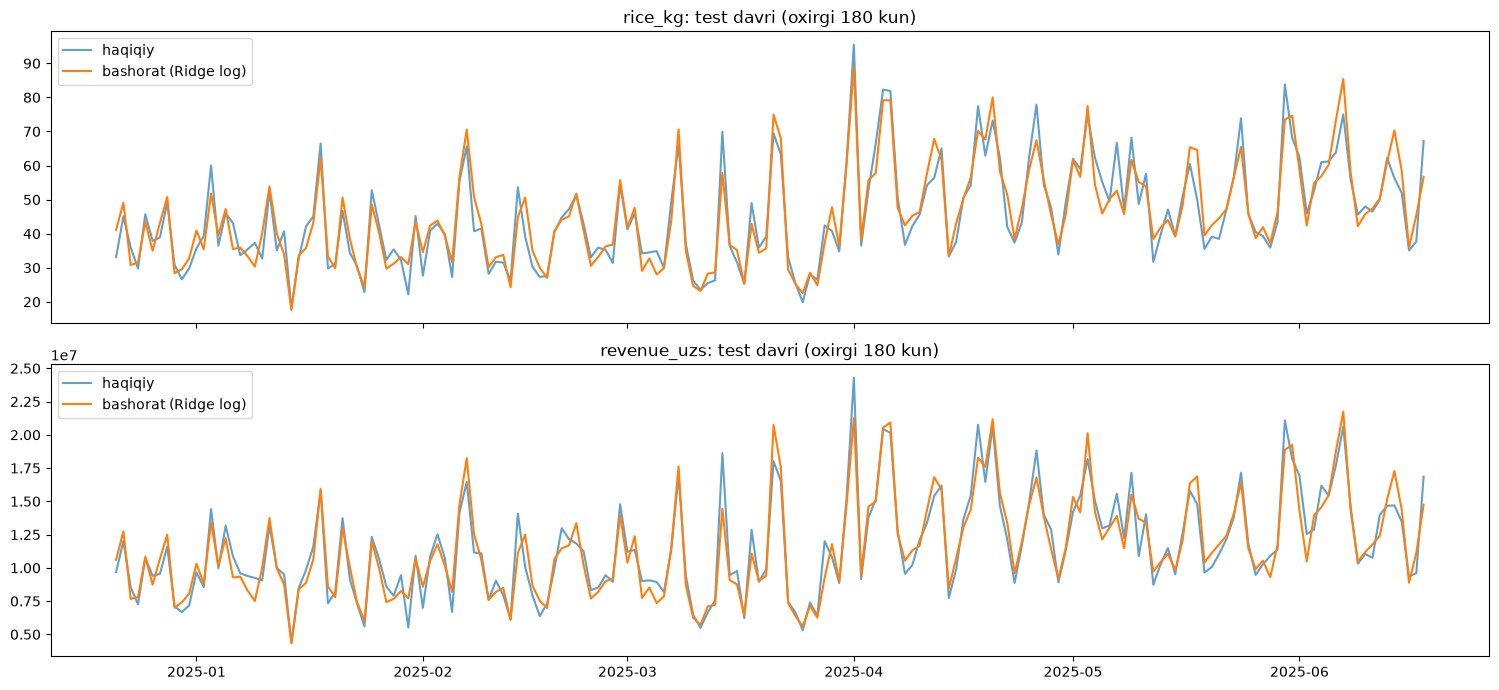

In [7]:
for t in TARGETS:
    m = ridge_models[t]
    tr_err = np.mean(np.abs(train[t] / np.exp(m.predict(X_train)) - 1)) * 100
    te_err = np.mean(np.abs(test[t] / np.exp(m.predict(X_test)) - 1)) * 100
    print(f"{t:<12} train'dagi xato: {tr_err:.1f}%   test'dagi xato: {te_err:.1f}%")

fig, ax = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for a, t in zip(ax, TARGETS):
    pred = np.exp(ridge_models[t].predict(X_test))
    a.plot(test.date, test[t], label="haqiqiy", alpha=0.7)
    a.plot(test.date, pred, label="bashorat (Ridge log)")
    a.set_title(f"{t}: test davri (oxirgi 180 kun)"); a.legend()
plt.tight_layout(); plt.show()

### Javob: yo'q, mavjud ma'lumot bilan halol 95% bo'lmaydi

- Eng yaxshi natijalar: guruch **~91.5%**, tushum **~92.5%** aniqlik.
- Model **o'zi o'rgangan train ma'lumotida ham** ~7–7.5% xato qiladi va bu test xatosiga (7.5–8.3%) juda yaqin. Demak, muammo model kuchsizligida emas: ma'lumotda ~8% **kunlik tasodifiy tebranish** bor. Sana, ob-havo va hodisalar uni tushuntira olmaydi, hech qaysi model (boosting ham, Keras ham) uni yo'q qila olmaydi.
- 95%+ natija faqat leakage bilan chiqadi va u real hayotda ishlamaydi (2-bo'lim).

**95% ga yaqinlashish uchun yangi ma'lumot kerak, yangi model emas:** oldindan bronlar va buyurtmalar, tadbirlar tafsiloti (ishtirokchilar soni), ko'proq yillik tarix.

**Amaliy yechim:** aniq son o'rniga **95% ishonch oralig'i** beramiz. Haqiqiy qiymat 100 kundan ~95 tasida shu oraliqqa tushadi.

## 5. Tayyor model: `model/sales_model.joblib`

`model/train.py` aynan yuqoridagi Ridge (log) modelini **barcha 900 kunda** qayta o'qitadi va 95% oraliq bilan birga saqlaydi. Ertangi kun uchun bashorat:

In [8]:
tomorrow = pd.read_csv("../model/example_tomorrow.csv")
tomorrow

,date,temp_c,humidity,wind,rain,snow,is_holiday,ramadan,eid,salary_week,promotion,local_event,football_match
0,2025-06-19,34.0,45.0,3.0,False,False,False,False,False,False,False,False,False
1,2025-06-20,33.0,42.0,2.5,False,False,False,False,False,True,True,False,False
2,2025-06-21,31.0,50.0,4.0,True,False,False,False,False,True,False,False,True


In [9]:
forecast = predict(tomorrow, bundle=__import__("joblib").load("../model/sales_model.joblib"))
forecast

,date,rice_kg,rice_kg_min,rice_kg_max,revenue_uzs,revenue_uzs_min,revenue_uzs_max
0,2025-06-19,49.8,39.9,60.1,12436000.0,10325000.0,15011000.0
1,2025-06-20,98.8,79.1,119.1,25277000.0,20986000.0,30511000.0
2,2025-06-21,81.5,65.3,98.2,21255000.0,17647000.0,25657000.0


## Yakuniy xulosa

| | Guruch (kg) | Tushum (so'm) |
|---|---|---|
| Eng yaxshi model | Ridge (log target) | Ridge (log target) |
| Aniqlik (test, 180 kun) | **91.5%** | **92.5%** |
| O'rtacha xato | ±3.8 kg | ±0.87 mln so'm |
| 95% oraliq | bashorat × 0.80 … 1.21 | bashorat × 0.83 … 1.21 |
| 95% aniqlik | ❌ shovqin ~8% | ❌ shovqin ~8% |

**Tavsiyalar:**
- Guruchni bashorat va `rice_kg_max` oralig'ida tayyorlang: yetishmay qolish ortib qolishdan qimmatroq tushadi.
- Aksiyalarni talab past kunlarga qo'ying: dushanba–seshanba, Ramazon, qishki oylar.
- Modelni oyiga bir marta yangi ma'lumot bilan qayta o'qiting: `python train.py --data ...`.